In [2]:
import pandas as pd 


In [3]:
df = pd.read_csv('netflix_titles.csv')

In [4]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [6]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

Column description
show_id = unique id 
type = tv show or movie
title = content title
director - director of tv show or movie
cast - actors 
country - country
date_added - on which date added to netflix(new content)
release_year - release year (old content)
rating - rating ''' 
Tv-MA - mature audience
Tv-14 - suitable above 14
pg - parentel guidance
pg-13 - parents strongly cautioned
R - restricted
Tv-Y - kids
Tv-Y7 - Kids above 7
NR - Not Rated
G - General Audience
TV-Y7-FV	Kids 7+, fantasy violence
NC-17	Adults only (17+)
UR -	Unrated
duration - duration 
listed_in - Genres
description - Summary 
Numerical Col:
release_year
duration_num 
Categorical col:
type
title
director
cast
country
rating
listed_in
Mixed col:
duration 


In [9]:
df.to_excel('netflix_titles.xlsx',index=False)

Conclusion
'title'
conclusion 
- some duplicate and yes or no xx type value 
'director'
missing value
'cast'
missing value
'country'
missing value
'date added'
str -> date time
missing value 
rating
missing value
'duration'
missing value
duration in season and min so we gonna split this two value 
release_yer
int -> date time

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   show_id       8807 non-null   str  
 1   type          8807 non-null   str  
 2   title         8807 non-null   str  
 3   director      6173 non-null   str  
 4   cast          7982 non-null   str  
 5   country       7976 non-null   str  
 6   date_added    8797 non-null   str  
 7   release_year  8807 non-null   int64
 8   rating        8803 non-null   str  
 9   duration      8804 non-null   str  
 10  listed_in     8807 non-null   str  
 11  description   8807 non-null   str  
dtypes: int64(1), str(11)
memory usage: 825.8 KB


date_added :
col   August 4, 2017"

Notice the space before August.

So first remove spaces, then convert

In [21]:
df['date_added'] = pd.to_datetime(df['date_added'].str.strip())

univariate analysis

In [24]:
df['type'].value_counts()

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

In [25]:
df['type'].isnull().sum()

np.int64(0)

<Axes: >

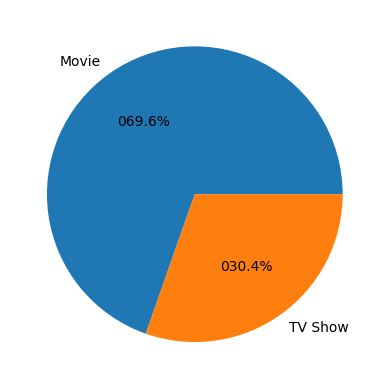

In [26]:
df['type'].value_counts().plot(kind='pie',autopct='0%.1f%%')

The Netflix dataset is dominated by Movies, with Movies accounting for around 70% of total content while TV Shows account for approximately 30%.

In [30]:
df['title'].sample(5)

4174                    Innocent
7752            Playing for Time
8297    The Figurine (Araromire)
1327            This Is the Life
3866             The Last Summer
Name: title, dtype: str

In [31]:
df['title'].isnull().sum()

np.int64(0)

In [34]:
df['title'].duplicated().sum()

np.int64(0)

In [41]:
df['director'].value_counts()



director
Rajiv Chilaka              19
Raúl Campos, Jan Suter     18
Suhas Kadav                16
Marcus Raboy               16
Jay Karas                  14
                           ..
Mu Chu                      1
Chandra Prakash Dwivedi     1
Majid Al Ansari             1
Peter Hewitt                1
Mozez Singh                 1
Name: count, Length: 4528, dtype: int64

3661 director only 1 movie

In [46]:
df['director'].duplicated().sum()
df['director'].value_counts()[df['director'].value_counts() == 1].sum()

np.int64(3661)

In [47]:
(df['director'].isnull().sum()/len(df))*100

np.float64(29.908027705234474)

In [51]:
df['director'] = df['director'].fillna('Unknown')

In [54]:
df.columns
# '''
# cast', 'country', 'date_added',
#        'release_year', 'rating', 'duration', 'listed_in', 'description'],
#       dtype='str')

#       '''

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'listed_in', 'description'],
      dtype='str')

In [58]:
(df['cast'].isnull().sum()/len(df))*100

np.float64(9.367548540933349)

In [60]:
df['cast'].value_counts()

cast
David Attenborough                                                                                                                                             19
Vatsal Dubey, Julie Tejwani, Rupa Bhimani, Jigna Bhardwaj, Rajesh Kava, Mousam, Swapnil                                                                        14
Samuel West                                                                                                                                                    10
Jeff Dunham                                                                                                                                                     7
David Spade, London Hughes, Fortune Feimster                                                                                                                    6
                                                                                                                                                               ..
Ali Suliman, Saleh Bakr